# PTM3D notebook 04: (101955) Bennu on its SPICE ephemeris

This notebook uses a body defined in the configuration, as in [notebook 03](03_asteroid_thermal.ipynb),
but replaces the two-body orbit with a SPICE ephemeris and the sphere with a measured shape model.
The body is (101955) Bennu, from which OSIRIS-REx returned a sample.

The two-body orbit of notebook 03 is exact for the Sun and an isolated asteroid with fixed
orbital elements. A SPICE ephemeris holds a trajectory fitted to observations, which already
includes the perturbations by the planets. Use one when a result has to match a real date, a real
distance and phase angle, or the geometry of a mission. Section 6 shows how much difference it
makes for Bennu.

**Cost:** four runs on the 49,152-facet OSIRIS-REx shape model, with two rotations of output after
about 40 rotations of spin-up. They take about half an hour on four cores and a few minutes on a
workstation.

**Needs:** the `ptm` package, a built `ptm_thermal_sim`, and
`python3 scripts/fetch_kernels.py --bodies bennu`, which downloads the general SPICE kernels and
Bennu's ephemeris (81 MB). Bennu's meta-kernel and its two shape models are in the repository.
Section 3 describes where each file comes from and how to find the same files for another body.

In [1]:
from ptm import paths, plots, run as engine

# Resolution of the figures stored in the notebook.
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "dpi": 100}

CONFIG = "examples/quickstart_asteroid_bennu.yaml"
BODY = "data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)"
pre = paths.preflight([CONFIG, "data/kernels/bennu.tm", "data/kernels/lsk/naif0012.tls",
                       "data/kernels/spk/de440s.bsp", f"{BODY}/ephemeris.spk",
                       f"{BODY}/bennu_radar_shape.obj"], engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()

found    <repo>/build/bin/ptm_thermal_sim
found    examples/quickstart_asteroid_bennu.yaml
found    data/kernels/bennu.tm
found    data/kernels/lsk/naif0012.tls
found    data/kernels/spk/de440s.bsp
found    data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/ephemeris.spk
found    data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/bennu_radar_shape.obj

Repo root: <repo>
Engine:    <repo>/build/bin/ptm_thermal_sim


<Report 7/7 found>

## 1. Bennu at perihelion, 2019 January 10

The perihelion nearest the middle of the OSIRIS-REx proximity operations is on 2019 January 10,
at 0.897 AU from the Sun. It was found by sampling Bennu's ephemeris once a day. Section 5 uses the
following aphelion.

In [2]:
perihelion = engine.run_engine(pre.root / CONFIG, echo=True)
peri = perihelion.results(body_radius_km=0.2447)

Running: <repo>/build/bin/ptm_thermal_sim --config <repo>/examples/quickstart_asteroid_bennu.yaml
(cwd=<repo>)

╔═══════════════════════════════════════════════════════════════╗
║    *      .    *     \   ||    //      * .   .      *         ║
║       .      *     \  \  ||   //    //       .             .  ║
║  *      .       \   \  \  ☀  //    //      .      *           ║
║     .         *  \   ...-'''''-...//    *         .           ║
║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
║  ═══════════════════════════════════════════════════════════  ║
║      Coupled Thermal-Illumination for Planetary Bodies        ║
╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: <repo>/examples/quickstart_asteroid_bennu.yaml
✓ Configuration loaded from: <repo>/examples/quickstart_asteroid_bennu.yaml
[gpu] Thermal dispatch target: 1.5 s (default)
Note: body '101955

Successfully loaded 25350 vertices and 49152 faces from OBJ file
Mesh hemisphere detection: Average latitude is 0.00° (Northern hemisphere)
Mesh hemisphere detection: Northern hemisphere
All face normals already point outward
[mesh-units] inferred KILOMETERS: median |face_center| = 0.239777204 (range 0.2145068748 .. 0.2887708304), 49152 faces, R_body = 0.2437 km
[mesh-units]   confirmed by R_body: |face_center| / R_body = 0.98 assuming KILOMETERS
[lateral-advisor] not needed: the median facet (6.25 m) is 199 times D*(50 K) = 3.15 cm, so facets are conductively isolated and exchange heat by radiation.
[lateral-advisor]   D* = 8k/(pi h), h = 4 eps sigma T^3 + Gamma sqrt(omega), from this run's surface material (101955 Bennu (1999 RQ36) surface layer): k(T) Hayne et al. 2017 with chi = 0, k_s = 0.075 W/m/K, rho_s = 1500 kg/m^3, eps = 0.95, solar day 0.1791 d
[lateral-advisor]   D* = 1.61 cm at 300 K (sunlit), 3.02 cm at 110 K (water-ice threshold), 3.15 cm at 50 K (cold trap)
[lateral-adv

[provenance] output/quickstart_asteroid_bennu/provenance.txt  engine 1.1 @ c945cca70c, md5 e29902b7a008f3915f8901e309809993
Setting up illumination model...
Configured generic body '101955 Bennu (1999 RQ36)' with SPICE ephemeris (kernel: bennu.tm, NAIF ID: 2101955, Keplerian fallback: enabled)
Illumination model configured for generic body: 101955 Bennu (1999 RQ36) (SPICE ephemeris)
SPICE kernel directory: <repo>/data/kernels  (compiled-in SPICE_KERNELS_DIR)
Initializing SPICE with meta-kernel
Loaded SPICE meta-kernel: <repo>/data/kernels/bennu.tm
========== Thermal Equilibration Configuration ==========
Body: 101955 Bennu (1999 RQ36)
Synodic day (solar day): 0.18 Earth days
Equilibration (configured): 40.00 day/night cycles  (thermal.equilibration_orbits)
Equilibration (integrated): 40.00 day/night cycles = 1 pass(es) x 40.00-cycle forcing block  [default]
Seed surface anchor: lumped  (cycle-mean lumped-substrate anchor; the run's per-face census and its QUADRATURE are printed by the 

[ephemeris] SPK coverage for 2101955 (NAIF 2101955, 1 kernel(s), 1 interval(s)): 1899-12-31T23:59:19 .. 2135-09-30T23:58:51 -- contains the run window 2019-01-02T20:01:53 .. 2019-01-10T08:33:01.
Running illumination simulation for 7.52 days (including 7.17 days equilibration) starting at 2019-01-02T20:01:53
[Embree] 4.3.3  traversal kernels: SSE (4-wide)  (native packets 4=yes 8=no 16=no)
[Embree] WARNING: this CPU has AVX but this Embree has no AVX kernels.
Ray traversal is running SSE2 BVH4 and is ~83 % of the
illumination phase. A multi-ISA build of the SAME Embree
version measured -7.0 % on the illumination phase of this
project's calib120 arm (18 paired repeats, 18/18 same sign,
2026-08-15). This is the Homebrew embree default.
Speed only -- but NOT result-neutral: on a lunar polar DEM
patch the ISA swap moved 75 of 260 output files, worst
face-frame |dT| 0.0091 K, because grazing occlusion verdicts
differ between ISA kernels. See INSTALL.md,
"Embree ISA (performance)".
[Illuminat

Initialized chunked storage with 1 chunks of up to 1000000 faces each


Calculating illumination:  [>                                                 ] 0% | elapsed 0s


... (13 outputs left out)

Progress 109/192


Progress 163/192


Progress 192/192
Export complete: 192/192
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_asteroid_bennu
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
Face count: 49152
Time steps: 192
Computing illumination statistics...
Computing direct solar statistics...
Computing primary reflected statistics...
Computing primary IR statistics...
Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_asteroid_bennu/statistics
[albedo] effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.017 over 49142/49152 ever-lit faces; per-face -> output/quickstart_asteroid_bennu/statistics/effective_albedo.bin (uint32 n + float32[49152], NaN where never lit).
Reduced over the INTEGRATION window, abs steps [1921,2113) -- the same win

Memory cleanup completed.
Cleaning up remaining memory...
Cleanup completed successfully

--- 486 output lines; 89.8 s wall; exit code 0 ---


## 2. Temperature on the shape model

`plot_shape` draws the run's own facets. `plot_globes`, used in the other
notebooks, projects the vertices onto a sphere, which is correct for an icosphere but not for
Bennu's spinning-top shape.

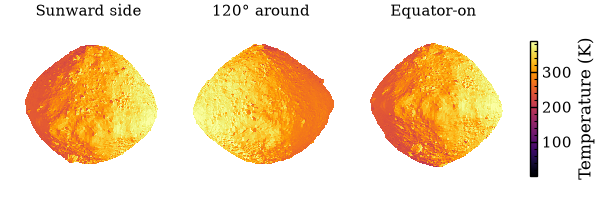

In [3]:
VIEWS = [(20, 155, "Sunward side"), (20, 275, "120° around"), (0, 155, "Equator-on")]
fig = peri.plot_shape(step=144, views=VIEWS, figsize=(plots.DOUBLE_W, 2.6))
for panel in fig.axes[:len(VIEWS)]:
    panel.set_box_aspect((1, 1, 1), zoom=1.4)   # fill the panel with the body

Bennu's equatorial ridge and flattened poles shape the temperature field. On the sphere of
notebook 03, every face at a given latitude had the same geometry. Here each face has its own tilt
toward the Sun and its own neighbors, so the diurnal cycle at each face depends on its slope and on
shadows from nearby terrain. That is why the terminator is irregular.

## 3. Data sources

A real body needs three kinds of data, all under `data/`. These are the general kernels used for
every body, a meta-kernel for the body, and the body's own ephemeris and shape. The shape is found
by hand, and this section records how. The ephemeris is downloaded by
`scripts/fetch_kernels.py --bodies bennu`. It is JPL solution 118, covering 1900 to 2135. The
archived mission solution examined in the SPICE cells below is solution 76, which differs from it
by at most 13.9 km over this window, equivalent to about 2e-4 K.

### Shape: DAMIT first, then the PDS Small Bodies Node

`damit.DAMITClient` searches [DAMIT](https://damit.cuni.cz/), the database of asteroid shape
models from lightcurve inversion. Bennu's shape models do not come from lightcurve inversion. They
come from radar imaging and, after the spacecraft arrived, from the OSIRIS-REx laser altimeter. The
search below therefore returns nothing.

In [4]:
from damit import DAMITClient

damit = DAMITClient()
for query in ("Bennu", "101955"):
    for attempt in range(3):      # the service sometimes fails one page of a search
        try:
            print(f"DAMIT search({query!r}) -> {len(damit.search_asteroid(query))} match(es)")
            break
        except Exception as exc:  # offline, or DAMIT down: the runs use the cached shape files
            error = f"{type(exc).__name__}: {exc}"
    else:
        print(f"WARNING: DAMIT did not answer the search for {query!r} ({error}). The shapes "
              "used in this notebook are the cached files under data/horizons_cache.")

DAMIT search('Bennu') -> 0 match(es)


DAMIT search('101955') -> 0 match(es)


With no match in DAMIT, the shape models come from the PDS Small Bodies Node. The record below is
for the radar model made before the spacecraft arrived:
[PDS SBN, shape model of asteroid (101955) Bennu](https://sbn.psi.edu/pds/resource/bennushape.html),
`urn:nasa:pds:ast-bennu.radar.shape-model::1.1`, from Nolan, M. C. et al. (2013), *Shape model
and surface properties of the OSIRIS-REx target asteroid (101955) Bennu from radar and lightcurve
observations*, Icarus 226, 629-640,
[doi:10.1016/j.icarus.2013.05.028](https://doi.org/10.1016/j.icarus.2013.05.028). These are NASA
PDS archival data in the public domain. Cite the paper when you use them.

The archive's `data/101955bennu.tab` uses the same `v x y z` and `f i j k` format as DAMIT shape
files, and `damit.shape_converter` reads either. The pole (ecliptic $\lambda = 45^\circ$,
$\beta = -88^\circ$) and the rotation period (4.29746 h, Hergenrother et al., 2013) come from the
same archive. They are converted to equatorial coordinates for `generic_body.spin` in the same way
as a DAMIT model's. The converted file carries the citation in its header.

The runs in this notebook use the later OSIRIS-REx laser altimeter model,
`g_06370mm_alt_obj_0000n00000_v021.obj` (OLA version 21, 6.37 m sampling, 49,152 facets), in the same
directory. Its source and checksums are in
`data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/PROVENANCE.md`.

In [5]:
shape = pre.root / BODY / "bennu_radar_shape.obj"
print("\n".join(l for l in shape.read_text().splitlines() if l.startswith("#")))

# Wavefront OBJ shape model -- asteroid (101955) Bennu
#
# Source: Nolan, M.C., Magri, C., Howell, E.S., Benner, L.A.M., Giorgini, J.D.,
#   Hergenrother, C.W., Hudson, R.S., Lauretta, D.S., Margot, J.L., Ostro, S.J.,
#   Scheeres, D.J. (2013). Shape model and surface properties of the OSIRIS-REx
#   target asteroid (101955) Bennu from radar and lightcurve observations.
#   Icarus 226, 629-640. doi:10.1016/j.icarus.2013.05.028
# Archive: PDS Small Bodies Node, urn:nasa:pds:ast-bennu.radar.shape-model::1.1
#   https://sbnarchive.psi.edu/pds4/non_mission/ast-bennu.radar.shape-model_V1_1.zip
#   NASA PDS archival data; public domain / freely redistributable with citation.
# Converted from the archive's native "v x y z / f i j k" vertex-facet table
# (data/101955bennu.tab) verbatim -- vertices already in km, center of mass
# origin, principal-axis frame, z = spin (long) axis. 1348 vertices, 2692
# facets, ~25 m vertex spacing. No decimation applied (already small).
#


### Ephemeris: an archived file rather than one generated on request

JPL Horizons can generate an ephemeris file (SPK) for most small bodies on request
(`horizons.HorizonsClient.download_spk`), but not for Bennu.

```
COMMAND='101955', EPHEM_TYPE=SPK, CENTER='500@0' ->
"SPK creation is not available for pre-computed objects in the major body index"
```

Horizons does not generate SPK files for a few small bodies whose orbits are known from spacecraft
tracking. For these, use an archived file. For Bennu that can be the mission's own
`bennu_refdrmc_v1.bsp` from the
[OSIRIS-REx SPICE archive](https://naif.jpl.nasa.gov/pub/naif/pds/pds4/orex/orex_spice/spice_kernels/spk/bennu_refdrmc_v1.bsp)
at the NAIF PDS4 node, or JPL's own solution, which `fetch_kernels.py` downloads.

Read the body's NAIF ID from the SPK rather than computing it from the asteroid number, because
small-body IDs have followed more than one numbering scheme.

In [6]:
import spiceypy as sp

sp.furnsh(str(pre.root / "data/kernels/lsk/naif0012.tls"))
sp.furnsh(str(pre.root / BODY / "ephemeris.spk"))
start, end = sp.spkcov(str(pre.root / BODY / "ephemeris.spk"), 2101955)
print(f"SPK declares target 2101955, covering {sp.et2utc(start, 'C', 0)} "
      f"to {sp.et2utc(end, 'C', 0)}")
sp.kclear()

SPK declares target 2101955, covering 2014 DEC 31 23:58:53 to 2023 MAY 30 23:58:51


### Meta-kernel search

`generic_body.spice_metakernel` is found as follows.

- An absolute path is used as given.
- A relative path is looked for first in the kernel directory (`data/kernels/`, unless
  `$PTM_SPICE_KERNELS` or the CMake setting `SPICE_KERNELS_DIR` names another), and then in the
  current directory.

`data/kernels/bennu.tm` is given by its file name alone, like `moon.tm`, `europa.tm` and
`mercury.tm`. It names the general kernels and Bennu's ephemeris. Every run prints the meta-kernel
it loaded (`Loaded SPICE meta-kernel: ...`). If none is found, the run stops and lists every path
it tried.

## 4. The configuration, compared with notebook 03

| | 03, Keplerian | 04, SPICE |
|---|---|---|
| `generic_body.ephemeris_source` | `keplerian` | `spice` |
| Sun-body vector | two-body orbit from `orbit:` | the SPK named in `bennu.tm`, corrected for light time and stellar aberration |
| `spice_metakernel`, `naif_id` | not used | required |
| `orbit:` block | gives the position | used only outside the time covered by the SPK |
| `shape.type` | `spherical`, radius only | `custom_mesh`, a measured shape |
| `spin` pole | illustrative values | Bennu's pole, obliquity about 178° (a fast retrograde rotator) |
| external data | leapseconds only | general kernels, the body's SPK, one shape file |

In [7]:
print((pre.root / CONFIG).read_text())

# PTM3D quickstart: asteroid (101955) Bennu on its real SPICE ephemeris, with
# the OSIRIS-REx mission shape model, near the 2019-01-10 perihelion of
# its orbit during the OSIRIS-REx proximity-operations era.
#
# Notebook counterpart of examples/quickstart_asteroid_diurnal.yaml (tutorial
# 03, Keplerian orbit, fictional body). This config is that notebook's SPICE
# counterpart: same generic-body thermal path, but the Sun-body vector comes
# from a real ephemeris file instead of an analytic two-body propagation, and
# the shape is Bennu's actual measured facet model instead of a sphere.
# See docs/tutorials/notebooks/04_asteroid_spice.ipynb for the full walkthrough.
#
# CPU-only and laptop-friendly, on a 49,152-facet mesh.
#
# Run FROM THE REPOSITORY ROOT:
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_asteroid_bennu.yaml
#
# ---------------------------------------------------------------------------
# Shape: data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/
# g_0637

As in notebook 03, the thermophysical properties of a body defined this way are read only from
`generic_body.surface:`. The values are Bennu's.

- Albedo 0.017, the bolometric Bond albedo from the OCAMS phase curve (Golish et al., 2021).
  Bennu's geometric albedo is 0.044, a very dark B-type surface.
- Thermal inertia $\Gamma = \sqrt{0.075 \times 1500 \times 800} = 300$ SI, the global value from
  OTES (Rozitis et al., 2020), with local values of 200 to 700 SI over fine material and boulders.
  The density and heat capacity are the regolith values of notebook 03, not measurements. Bennu's
  bulk density of about 1190 kg/m³ describes the whole rubble pile, not the surface layer.
- Rotation period 4.29746 h, pole at ecliptic (45°, -88°), equatorial (86.64°, -65.11°).

The start of the log confirms the kind of body, the meta-kernel and the NAIF ID.

In [8]:
banner = perihelion.lines.index(
    next(l for l in perihelion.lines if l.startswith("Using generic body")))
print("\n".join(perihelion.lines[banner:banner + 12]))

Using generic body: 101955 Bennu (1999 RQ36)
Semi-major axis: 1.12892 AU
Eccentricity: 0.204651
Spin period: 4.29746 hours
Orbit epoch: JD 2451545 TDB  (mean anomaly 36.23987194 deg at this epoch)
Spin epoch:  JD 2451545 TDB  (prime meridian W0 = 0 deg at this epoch)
Solar constant: 1067.9 W/m^2
Synodic day: 4.29922 hours
Albedo: 0.017
Emissivity: 0.95
Body radius: 0.2437 km
Ephemeris: SPICE


One line of the log needs a comment. `Solar constant` is computed at the fixed
`orbit.semi_major_axis_au` of the configuration, not at the distance from the ephemeris. It is
printed once at the start, from the Keplerian orbit block, and is the same at perihelion and
aphelion. The positions at each time step are in `body_positions.csv`, whose Sun vector comes from
the SPK, and the rest of the notebook reads them.

## 5. Perihelion and aphelion

Bennu's orbit ($a = 1.129$ AU, $e = 0.205$) changes the sunlight it receives by more than a factor
of two over its year. The aphelion after the perihelion above is 218 days later, on
2019 August 16. The second run is the same configuration with two options on the command line,
so no edited copy is needed.

In [9]:
import numpy as np

AU_KM = 1.495978707e8


def solar_distance_au(res):
    # Mean Sun-body distance over the output window, from body_positions.csv.
    p = res.body_positions()
    xyz = np.column_stack([p[f"sun_{a}"] for a in "xyz"])
    return float(np.linalg.norm(xyz, axis=1).mean() / AU_KM)


aph = engine.run_engine(pre.root / CONFIG, show=("Simulation completed in",),
                        extra_args=["--start", "2019-08-16T00:00:00", "--output",
                                    "output/quickstart_asteroid_bennu_aphelion"]
                        ).results(body_radius_km=0.2447)
r_peri, r_aph = solar_distance_au(peri), solar_distance_au(aph)
print(f"perihelion r = {r_peri:.4f} AU, aphelion r = {r_aph:.4f} AU, "
      f"insolation ratio {(r_aph / r_peri) ** 2:.2f}")

    Simulation completed in 96.360 seconds (96360 ms)
perihelion r = 0.8965 AU, aphelion r = 1.3553 AU, insolation ratio 2.29


perihelion : 8557 equatorial facets, mean 296.7 K, amplitude 139.2 K, peak at 13.25 h


aphelion   : 8557 equatorial facets, mean 246.4 K, amplitude 81.5 K, peak at 13.75 h


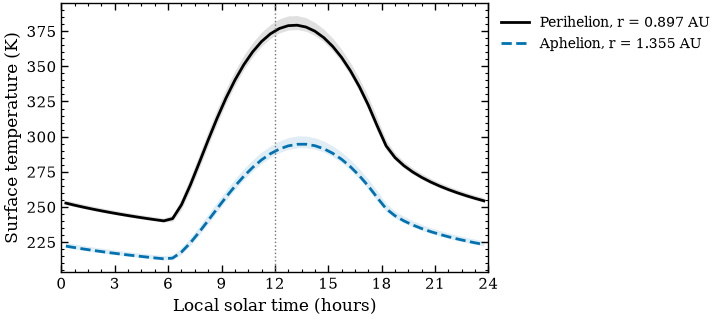

In [10]:
from ptm import plots

plt = plots.styled()
fig, ax = plt.subplots(figsize=(plots.DOUBLE_W, 3.2), layout="constrained")
for res, r_au, color, style, label in ((peri, r_peri, plots.PALETTE[0], plots.LINESTYLES[0], "Perihelion"),
                                       (aph, r_aph, plots.PALETTE[1], plots.LINESTYLES[1], "Aphelion")):
    steps = res.steps("temperature")
    lst, T, lo, hi, n_faces = res.local_solar_time_curve(steps=steps[len(steps) // 2:])
    ax.plot(lst, T, color=color, ls=style, label=f"{label}, r = {r_au:.3f} AU")
    ax.fill_between(lst, lo, hi, color=color, alpha=0.12, linewidth=0)
    print(f"{label.lower():11s}: {n_faces} equatorial facets, mean {T.mean():.1f} K, "
          f"amplitude {T.max() - T.min():.1f} K, peak at {lst[np.argmax(T)]:.2f} h")
ax.axvline(12, color="0.45", lw=1, ls=":")
ax.set_xlabel("Local solar time (hours)")
ax.set_ylabel("Surface temperature (K)")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 3))
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0));

The mean temperature at the equator follows the fourth-root law closely. The ratio of 296.7 K to
246.4 K is 1.20, and $2.29^{1/4} = 1.23$. The diurnal range does not. It falls by 41%, much more
than the fourth root, and the peak comes half an hour later. Both are effects of the thermal
parameter $\Theta \propto \Gamma\sqrt{\omega}/(\varepsilon\sigma T_{eq}^3)$, which grows as
$r^{3/2}$ as the body cools, so the same surface behaves as if its thermal inertia were higher
farther from the Sun. In notebook 03, $\Gamma$ was raised at a fixed distance. Here the distance is
raised at a fixed $\Gamma$, and the curve responds in the same way.

The shaded spread between facets is much wider than in notebook 03. That is the effect of the
shape. At the same local solar time, facets on a rubble pile do not all have the same geometry.

## 6. Accuracy of the ephemeris

The two-body orbit of notebook 03 uses fixed orbital elements from one epoch. Over a few orbits
that is nearly exact. Over years, perturbations by the planets, mainly Earth and Jupiter for a
near-Earth asteroid, move the real position away from the prediction. Bennu's configuration holds
its own orbital elements, fitted at J2000.0, in the Keplerian orbit block. Running the same
configuration with `ephemeris_source: keplerian` on the same date shows the difference.

In [11]:
import yaml

kep_config = yaml.safe_load((pre.root / CONFIG).read_text())
kep_config["generic_body"]["ephemeris_source"] = "keplerian"
kep_config["output"]["directory"] = "output/_bennu_keplerian_check"
kep_path = pre.root / "output" / "_bennu_keplerian_check.yaml"
kep_path.parent.mkdir(exist_ok=True)
kep_path.write_text(yaml.safe_dump(kep_config, sort_keys=False))

kep = engine.run_engine(kep_path, show=("Simulation completed in",)
                        ).results(body_radius_km=0.2447)
r_kep = solar_distance_au(kep)
print(f"2019-01-10, identical shape, spin and thermal properties; only the "
      f"position source differs.\n"
      f"  SPICE ephemeris    : r = {r_peri:.4f} AU\n"
      f"  Keplerian fallback : r = {r_kep:.4f} AU\n"
      f"  difference         : {(r_kep - r_peri) * AU_KM:,.0f} km, "
      f"{100 * (r_kep - r_peri) / r_peri:.2f}% in distance, "
      f"{100 * (1 - (r_peri / r_kep) ** 2):.1f}% in insolation")

    Simulation completed in 83.441 seconds (83441 ms)
2019-01-10, identical shape, spin and thermal properties; only the position source differs.
  SPICE ephemeris    : r = 0.8965 AU
  Keplerian fallback : r = 0.9088 AU
  difference         : 1,829,182 km, 1.36% in distance, 2.7% in insolation


Nineteen years after the epoch of the elements, the two-body orbit is off by more than a million
kilometers, about 1% in distance and 3% in sunlight. That is small, but it is larger than the
accuracy needed for a mission at a particular time, for planning observations at a particular phase
angle, for example. The correction for light time and stellar aberration in the SPICE path is a
detail of the same kind, and it is why the navigation team's trajectory is the right source for
such work.

The thermal model is the same in the two runs, so the difference enters only through the distance
from the Sun. At 1.4% it is an error in the flux, not in the shape of the curve. The aphelion run of
section 5, a 51% change in distance, shows the effect of a large error.

## 7. Sensitivity to the measured thermal inertia

Every value in `generic_body.surface:` is used (`albedo`, `emissivity`, `ks`, `kd`, `rhos`, `rhod`,
`cp0`, `H`, `Qb`, `chi`), and [notebook 03, section 4](03_asteroid_thermal.ipynb) shows how to change
one and confirm the change. Bennu's values are measurements, and measurements have ranges. OTES
gives a global $\Gamma = 300$ SI, the value in the configuration, with local values from about 200
SI over fine material to 700 SI over boulders (Rozitis et al., 2020). The run below shows what that
range means in kelvin.

At fixed $\rho_s c_p$, $\Gamma \propto \sqrt{k_s}$, so 700 SI corresponds to
$k_s = k_d = \Gamma^2 / (\rho_s c_p) = 0.408$ W/m/K. `derived=` keeps `kd` equal to `ks`, so the
column is uniform and $\Gamma$ is one number.

In [12]:
import hashlib

from ptm import Sweep

boulder = Sweep(pre.root / CONFIG,
                grid={"generic_body.surface.ks": [700.0 ** 2 / (1500.0 * 800.0)]},
                derived={"generic_body.surface.kd":
                         lambda params: params["generic_body.surface.ks"]},
                outdir=pre.root / "output/bennu_boulder_inertia",
                results_kwargs={"body_radius_km": 0.2447})
boulder.run()

for label, res in (("300 SI (OTES global)", peri),
                   ("700 SI (boulder end)", boulder.points[0].results)):
    steps = res.steps("temperature")
    lst, T, lo, hi, n_faces = res.local_solar_time_curve(steps=steps[len(steps) // 2:])
    digest = hashlib.md5(
        (res.path / "statistics" / "temperature_max.bin").read_bytes()).hexdigest()
    print(f"{label}: mean {T.mean():6.1f} K, amplitude {T.max() - T.min():6.1f} K, "
          f"peak at {lst[np.argmax(T)]:5.2f} h, {digest[:8]}")

[sweep] engine <repo>/build/bin/ptm_thermal_sim (md5 e29902b7a008f3915f8901e309809993)
[sweep] axis generic_body.surface.ks: 1 values -> config key generic_body.surface.ks
[sweep] derived: generic_body.surface.kd (from the caller's own relation)


[sweep] ok   ks-0p408333 (89.0 s)
[sweep] 1 complete, 0 failed, 0 skipped, 89.0 s


300 SI (OTES global): mean  296.7 K, amplitude  139.2 K, peak at 13.25 h, 3dfda754


700 SI (boulder end): mean  304.7 K, amplitude   86.8 K, peak at 13.75 h, d1b573e1


Over the measured range, the diurnal range at the equator falls from 139.2 K to 86.8 K, by 38%, the
mean rises by 8.0 K, and the peak comes half an hour later. Two conclusions follow.

A thermal model of Bennu is only as precise as its thermal inertia. Predicting a daytime
temperature to a few kelvin requires $\Gamma$ to be known much better than the range between
boulders and fine material, which is why OTES mapped it region by region. Conversely, the shape of
the curve depends strongly on $\Gamma$, so an observed curve constrains it, which is how it is
measured.

The perihelion and aphelion runs of section 5 changed the range by 41% without changing any
property, only the distance. Distance and thermal inertia enter the same dimensionless parameter,
so a fit with the wrong distance from the Sun puts the error into $\Gamma$. That is the reason to
use the SPICE ephemeris.

## 8. Exercises

1. The drift over the orbit. Section 6 compared the two orbits on one date. Repeat the comparison
   on several dates over the decade around the mission, changing only `--start` and `--output`, and
   plot the difference against the time since the epoch of the elements. Does it grow roughly
   linearly?

2. The effect of the shape. Run the sphere of notebook 03 at $\Gamma = 300$ SI, Bennu's value, and
   compare its diurnal range and phase with the perihelion curve of section 5. The difference is
   the effect of the shape.

3. The spin axis. With an obliquity near 178°, Bennu's poles receive very different sunlight over
   an orbit than its equator. A run over a full orbit (`simulation.duration_days` of about 438
   days) takes much longer than this notebook. Compare the seasonal range of a polar facet with that
   of the equatorial band.